# CCN figure

The purpose of this notebook is to make a combined figure for the CCN abstract in order to free up space.

## Imports

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from adaptive_bottleneck.utils import load_plot_config

## Config

In [2]:
LABEL_MODES  = ("feature", "position")
MODE_TITLES  = {"feature": "Feature", "position": "Position"}
ATTN_KIND    = "softmax"   # adjust as needed
shade        = "sem"

FIXED_RESULTS_PATH  = "../data/context_identification_full_sweep.json"
ONLINE_RESULTS_PATH = "../data/online_gamma_20seeds_sweep.json"
SAVE_PATH           = "../results/summary_figure.pdf"

EPOCH_START = 0
EPOCH_END   = 2500  # set to None for all epochs

## Helpers

In [3]:
def load_json(path):
    with open(path) as f:
        return json.load(f)

def collect_curves(seed_dict, key):
    return np.stack(
        [np.array(hist[key]) for hist in seed_dict.values()], axis=0
    )

def mean_err(curves, shade="sem"):
    mean = curves.mean(axis=0)
    std  = curves.std(axis=0, ddof=1) if curves.shape[0] > 1 else np.zeros_like(mean)
    err  = std / np.sqrt(curves.shape[0]) if shade == "sem" else std
    return mean, err

## Figure

In [4]:
def fill_fixed_gamma_col(axes_col, results, gammas, shade="sem"):
    """Fill a 2-panel column with fixed-gamma sweep accuracy curves."""
    cmap = cm.plasma
    norm = Normalize(vmin=min(gammas), vmax=max(gammas))

    for ax, lm in zip(axes_col, LABEL_MODES):
        for g in gammas:
            g_key     = str(g)
            seed_dict = results[lm][ATTN_KIND][g_key]
            curves    = np.stack(
                [np.array(hist["test_acc"], dtype=float)
                 for hist in seed_dict.values()], axis=0
            )
            m, e  = mean_err(curves, shade)
            epochs = np.arange(curves.shape[1])
            color  = cmap(norm(g))
            ax.plot(epochs, m, color=color, linewidth=1.5, alpha=0.95)
            ax.fill_between(epochs, m - e, m + e, color=color, alpha=0.20)

        ax.set_ylabel(f"{MODE_TITLES[lm]} test acc", fontsize=8)
        ax.set_ylim(0.0, 1.05)
        ax.grid(alpha=0.2)

    axes_col[-1].set_xlabel("Epoch", fontsize=8)
    return cmap, norm   # returned so caller can draw colorbar


def fill_online_gamma_col(axes_col, results,
                           epoch_start=0, epoch_end=None, shade="sem"):
    """Fill a 2-panel column with dual-axis accuracy + gamma trajectory."""
    acc_color = plt.cm.plasma(0.3)
    gam_color = plt.cm.plasma(0.75)

    twin_axes = []
    for ax_acc, mode in zip(axes_col, LABEL_MODES):
        acc_curves = collect_curves(results[mode], "test_acc")
        gam_curves = collect_curves(results[mode], "gamma")

        n_epochs = acc_curves.shape[1]
        end      = epoch_end if epoch_end is not None else n_epochs
        sl       = slice(epoch_start, end)
        epochs   = np.arange(epoch_start, end)

        acc_m, acc_e = mean_err(acc_curves[:, sl], shade)
        gam_m, gam_e = mean_err(gam_curves[:, sl], shade)

        # left axis — accuracy
        ax_acc.plot(epochs, acc_m, color=acc_color, linewidth=1.5, label="Test acc")
        ax_acc.fill_between(epochs, acc_m - acc_e, acc_m + acc_e,
                            color=acc_color, alpha=0.20)
        ax_acc.set_ylim(0.0, 1.05)
        ax_acc.set_ylabel(f"{MODE_TITLES[mode]} test acc", fontsize=8, color=acc_color)
        ax_acc.tick_params(axis="y", labelcolor=acc_color, labelsize=8)
        ax_acc.grid(alpha=0.2)

        # right axis — gamma
        ax_gam = ax_acc.twinx()
        ax_gam.plot(epochs, gam_m, color=gam_color, linewidth=1.5,
                    linestyle="--", label="$\\gamma$")
        ax_gam.fill_between(epochs, gam_m - gam_e, gam_m + gam_e,
                            color=gam_color, alpha=0.15)
        ax_gam.set_ylim(-0.05, 1.05)
        ax_gam.set_ylabel("$\\gamma$", fontsize=8, color=gam_color)
        ax_gam.tick_params(axis="y", labelcolor=gam_color, labelsize=8)

        lines  = ax_acc.get_lines() + ax_gam.get_lines()
        labels = [l.get_label() for l in lines]
        ax_acc.legend(lines, labels, fontsize=7, loc="center right")

        twin_axes.append(ax_gam)

    axes_col[-1].set_xlabel("Epoch", fontsize=8)
    return twin_axes


# ── Main figure ───────────────────────────────────────────────────────────────
def make_summary_figure(
    fixed_results_path = FIXED_RESULTS_PATH,
    online_results_path = ONLINE_RESULTS_PATH,
    save_path           = SAVE_PATH,
    gammas              = None,   # list of gamma values in fixed sweep
    epoch_start         = EPOCH_START,
    epoch_end           = EPOCH_END,
    shade               = "sem",
):
    fixed_results  = load_json(fixed_results_path)
    online_results = load_json(online_results_path)

    if gammas is None:
        # infer gamma values from the first label mode
        first_lm = LABEL_MODES[0]
        gammas = sorted(float(k) for k in fixed_results[first_lm][ATTN_KIND].keys())

    # ── Grid: 2 rows × 3 cols, width_ratios gives equal space to cols 1 & 2
    #    col 0 is intentionally left blank for Illustrator
    fig, axes = plt.subplots(
        2, 3,
        figsize=(12, 3.5),
        gridspec_kw={"width_ratios": [2, 1.35, 1], "hspace": 0.45, "wspace": 0.35},
    )

    # ── Col 0: blank — keep axes alive (preserves grid space) but strip decorations
    for ax in axes[:, 0]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    # ── Col 1: fixed-gamma sweep ─────────────────────────────────────────────
    cmap, norm = fill_fixed_gamma_col(axes[:, 1], fixed_results, gammas, shade)

    # colorbar anchored to col 1 only
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes[:, 1], location="right", pad=0.04, shrink=0.85)
    cbar.set_label("$\\gamma$", fontsize=9)
    cbar.ax.tick_params(labelsize=8)

    # ── Col 2: online gamma ──────────────────────────────────────────────────
    fill_online_gamma_col(axes[:, 2], online_results, epoch_start, epoch_end, shade)

    # ── Column headers ───────────────────────────────────────────────────────
    col_titles = ["(A) Task schematic", "(B) Fixed $\\gamma$ sweep", "(C) Learnable $\\gamma$"]
    for col, title in enumerate(col_titles):
        axes[0, col].set_visible(True)   # briefly re-enable col 0 for title
        axes[0, col].set_title(title, fontsize=10, fontweight="bold", pad=14)

    err_label = "SEM" if shade == "sem" else "STD"

    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved → {save_path}")
    plt.show()

Saved → ../results/summary_figure.pdf


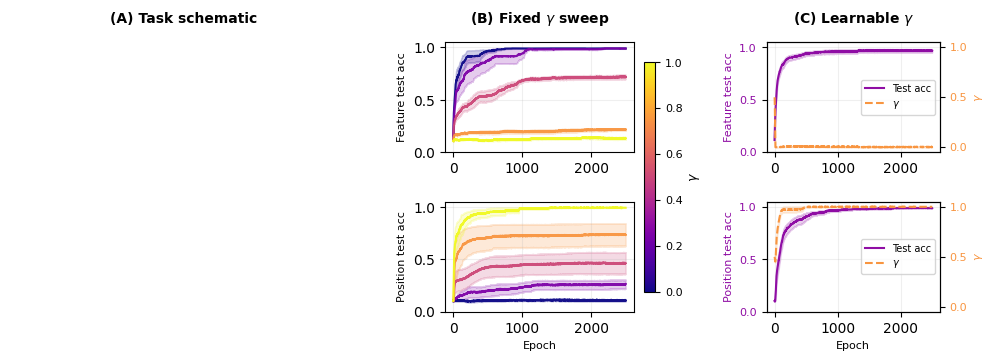

In [5]:
make_summary_figure(
    epoch_start=EPOCH_START,
    epoch_end=EPOCH_END,
    shade="sem",
)